# Practical Assignment 5: Ensemble Learning and Performance Evaluation

**Name:** Tejal Vijay Kadam  
**Division:** A  
**Roll No.:** 36  
**PRN:** 202401040153

## Section 1: Import Libraries and Load Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print(X.shape)
print(y.value_counts())
X.head()

(569, 30)
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Section 2: Train-Test Split

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## Section 3: Base Machine Learning Models

In [3]:
base_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'SVM': make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
    'Naive Bayes': GaussianNB()
}

results = {}
predictions = {}
probabilities = {}

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    if hasattr(model, 'predict_proba'):
        prob = model.predict_proba(X_test)[:, 1]
        probabilities[name] = prob
        auc = roc_auc_score(y_test, prob)
    else:
        auc = np.nan
    results[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
        'ROC-AUC': auc
    }

for name, model in base_models.items():
    evaluate(name, model)

pd.DataFrame(results).T.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
Decision Tree,0.9211,0.9565,0.9167,0.9362,0.9163
KNN,0.9561,0.9589,0.9722,0.9655,0.9788
SVM,0.9825,0.9861,0.9861,0.9861,0.9950
Naive Bayes,0.9386,0.9452,0.9583,0.9517,0.9878


## Section 4: Stacking Ensemble with Meta-Classifier

In [4]:
estimators = [
    ('lr', base_models['Logistic Regression']),
    ('dt', base_models['Decision Tree']),
    ('knn', base_models['KNN']),
    ('svm', base_models['SVM']),
    ('nb', base_models['Naive Bayes'])
]

stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,
    stack_method='predict_proba'
)

evaluate('Stacking Ensemble', stacking)
print(classification_report(y_test, predictions['Stacking Ensemble'], target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## Section 5: AdaBoost Ensemble

In [5]:
adaboost_stump = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

adaboost_tree = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

evaluate('AdaBoost (Stump)', adaboost_stump)
evaluate('AdaBoost (Depth-3 Tree)', adaboost_tree)

print(classification_report(y_test, predictions['AdaBoost (Stump)'], target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## Section 6: Voting Ensemble

In [6]:
voting_hard = VotingClassifier(
    estimators=estimators,
    voting='hard'
)

voting_soft = VotingClassifier(
    estimators=estimators,
    voting='soft'
)

evaluate('Voting (Hard)', voting_hard)
evaluate('Voting (Soft)', voting_soft)

print(classification_report(y_test, predictions['Voting (Hard)'], target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## Section 7: Performance Comparison of All Models

In [7]:
comparison = pd.DataFrame(results).T.round(4)
comparison = comparison.sort_values('F1-Score', ascending=False)
comparison

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
SVM,0.9825,0.9861,0.9861,0.9861,0.9950
Voting (Soft),0.9737,0.9600,1.0000,0.9796,0.9897
Voting (Hard),0.9737,0.9726,0.9861,0.9793,NaN
Stacking Ensemble,0.9737,0.9726,0.9861,0.9793,0.9917
AdaBoost (Depth-3 Tree),0.9649,0.9595,0.9861,0.9726,0.9911
AdaBoost (Stump),0.9561,0.9467,0.9861,0.9660,0.9835
KNN,0.9561,0.9589,0.9722,0.9655,0.9788
Naive Bayes,0.9386,0.9452,0.9583,0.9517,0.9878
Decision Tree,0.9211,0.9565,0.9167,0.9362,0.9163


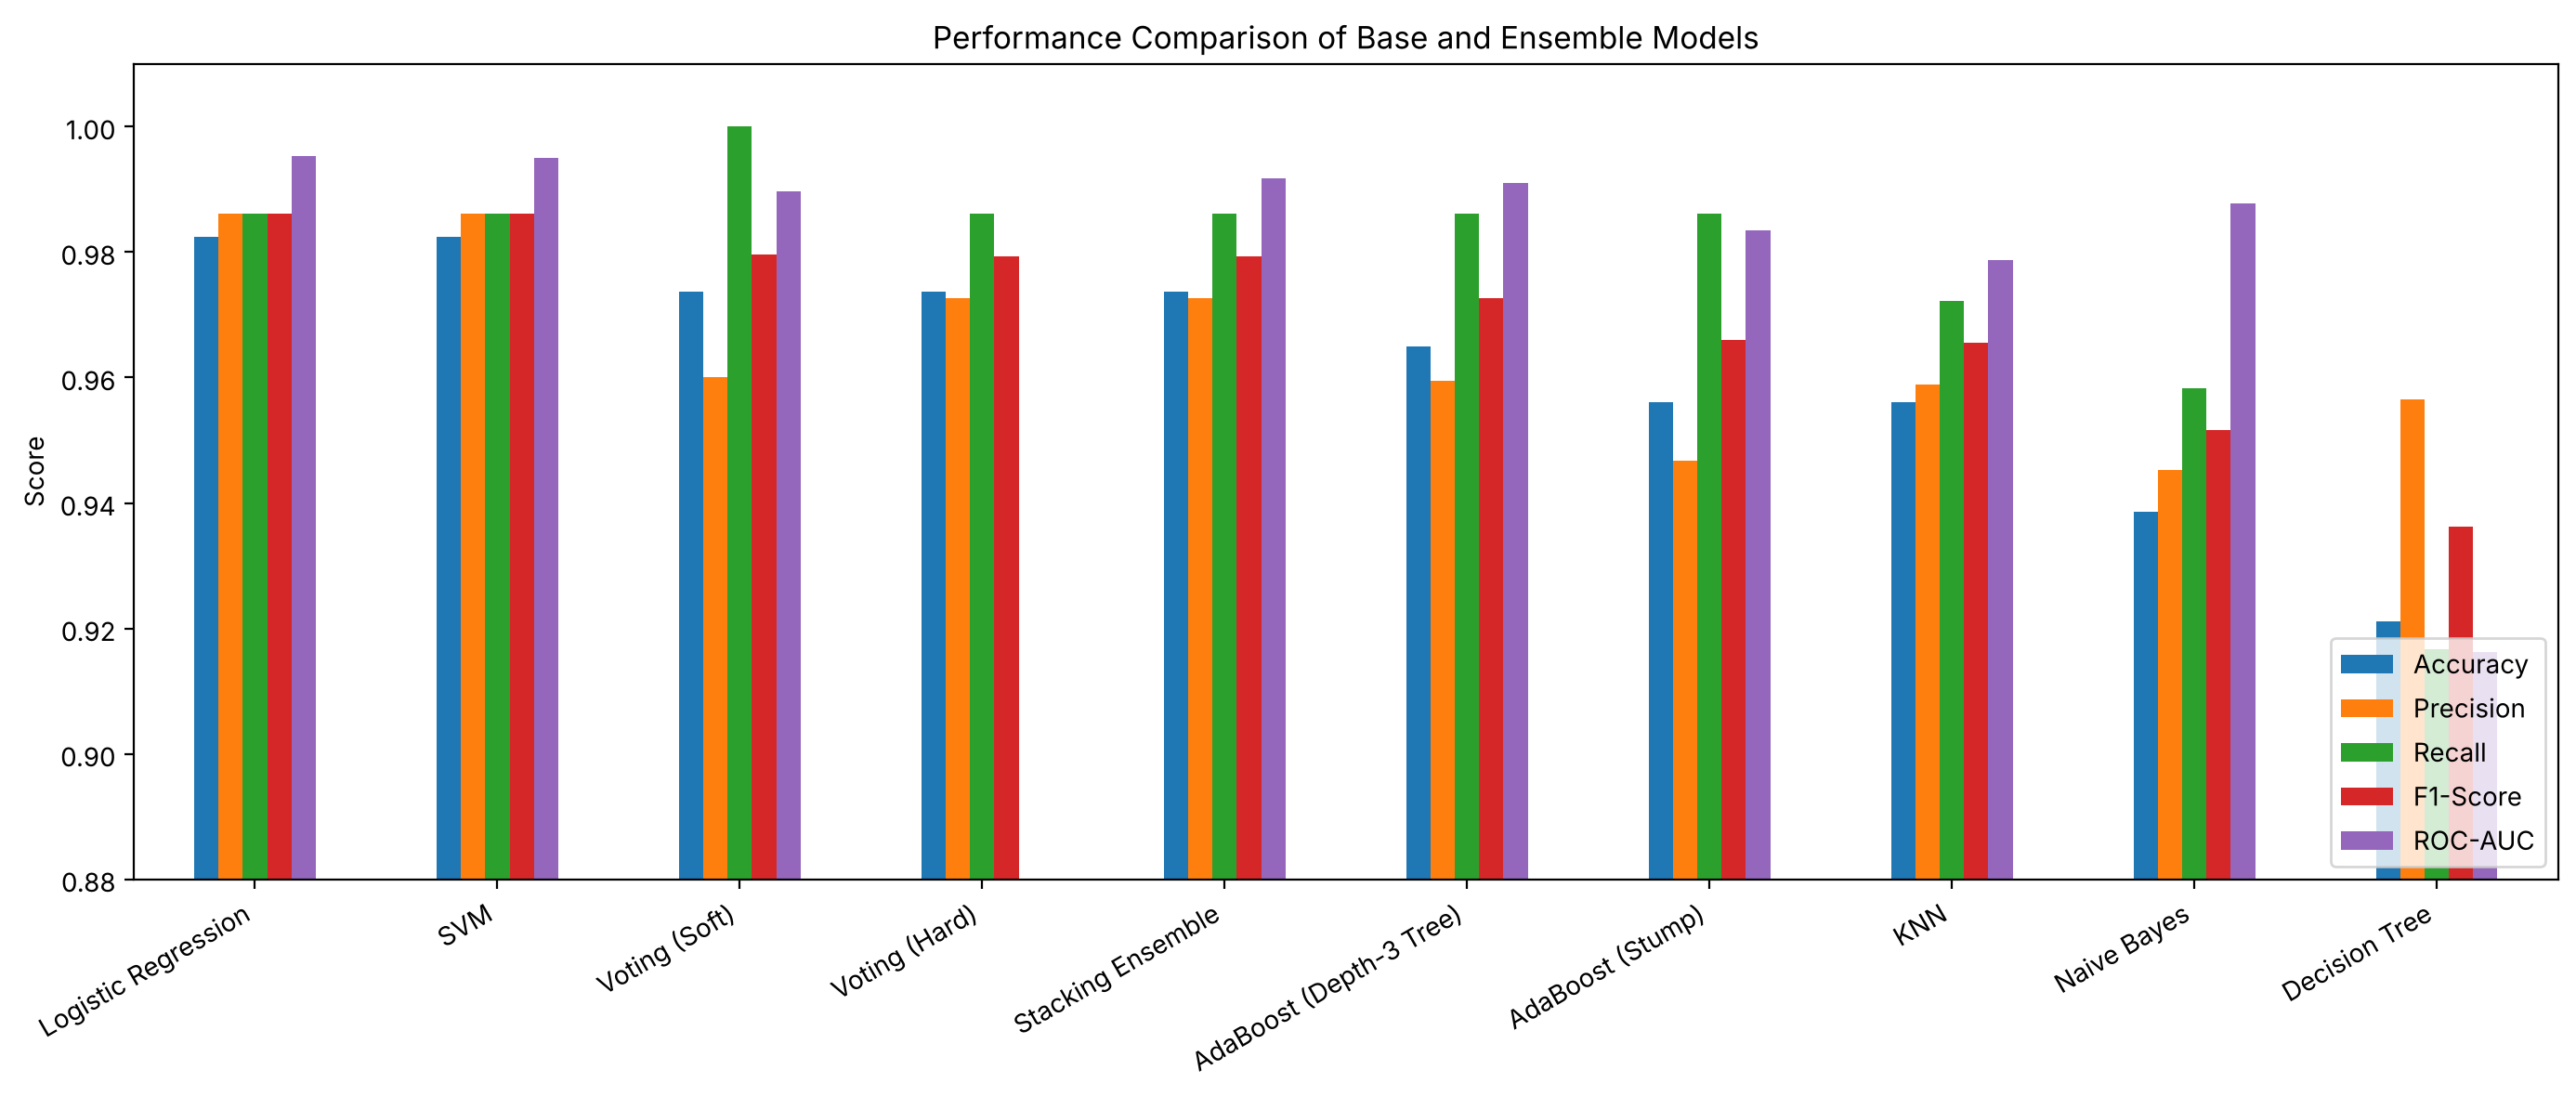

In [8]:
comparison.plot(kind='bar', figsize=(14, 6), ylim=(0.88, 1.01))
plt.title('Performance Comparison of Base and Ensemble Models')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

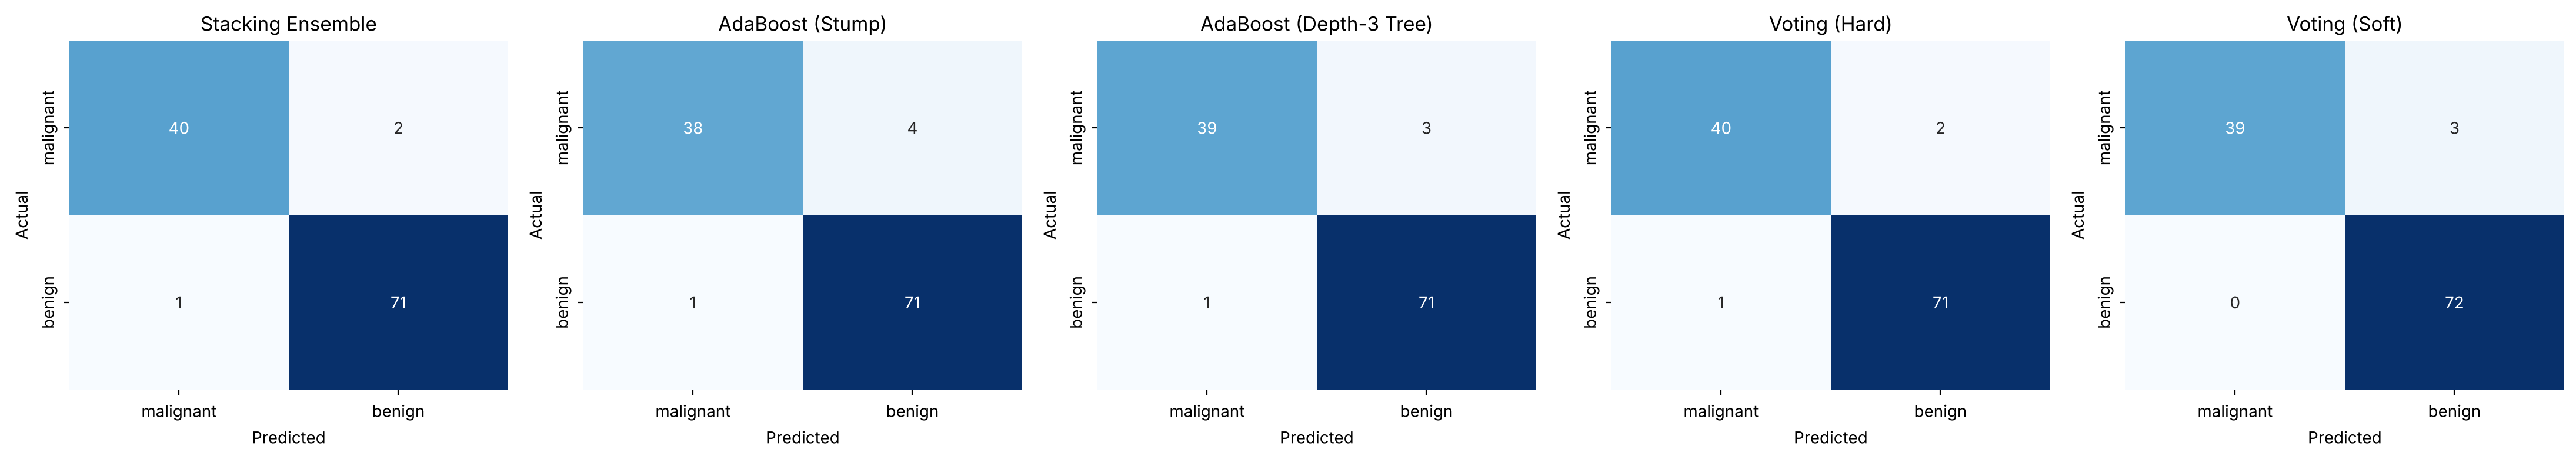

In [9]:
ensemble_names = ['Stacking Ensemble', 'AdaBoost (Stump)', 'AdaBoost (Depth-3 Tree)', 'Voting (Hard)', 'Voting (Soft)']

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, name in zip(axes, ensemble_names):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=data.target_names, yticklabels=data.target_names)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

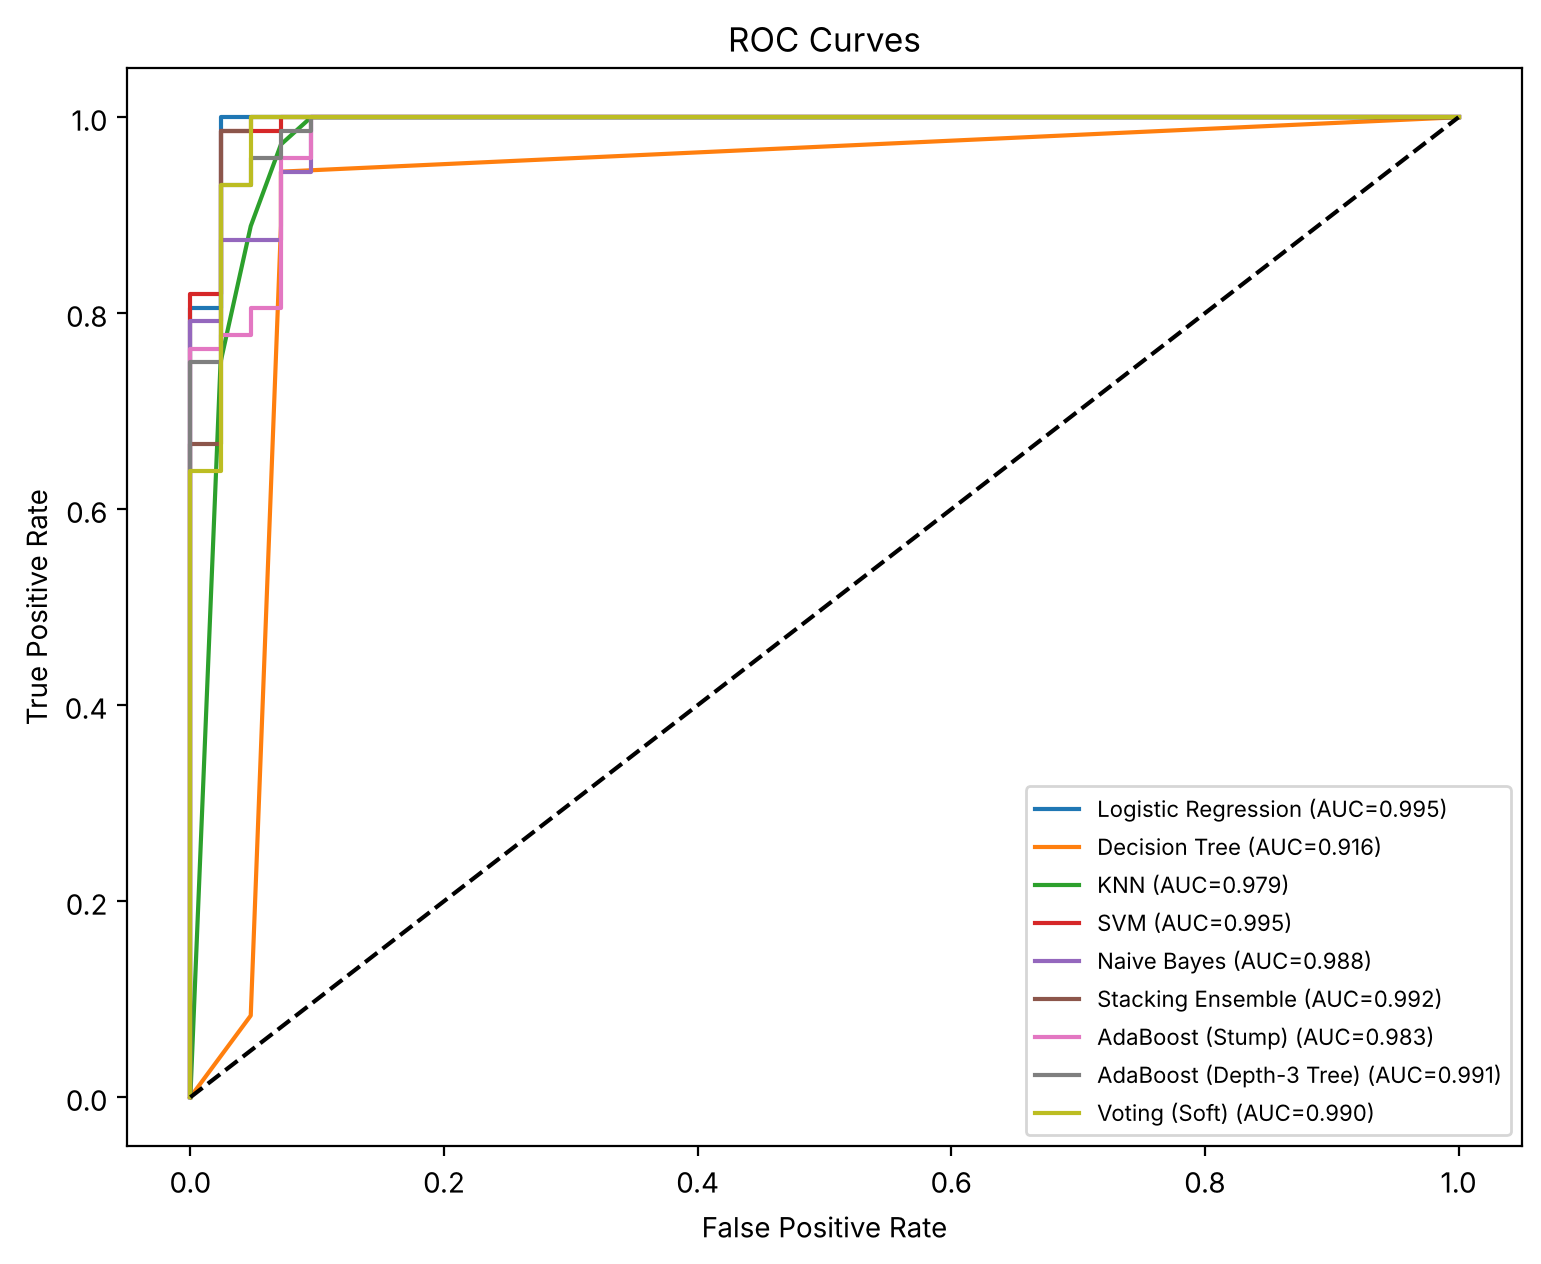

In [10]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 7))
for name in probabilities:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right', fontsize=8)
plt.show()

## Section 8: Cross-Validation Check

In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

all_models = dict(base_models)
all_models.update({
    'Stacking Ensemble': stacking,
    'AdaBoost (Stump)': adaboost_stump,
    'AdaBoost (Depth-3 Tree)': adaboost_tree,
    'Voting (Hard)': voting_hard,
    'Voting (Soft)': voting_soft
})

cv_results = {}
for name, model in all_models.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring='f1')
    cv_results[name] = {'Mean F1': scores.mean(), 'Std': scores.std()}

pd.DataFrame(cv_results).T.round(4).sort_values('Mean F1', ascending=False)

,Mean F1,Std
SVM,0.9820,0.0128
Voting (Hard),0.9795,0.0121
Logistic Regression,0.9794,0.0127
Stacking Ensemble,0.9779,0.0078
AdaBoost (Depth-3 Tree),0.9764,0.0103
KNN,0.9712,0.0138
Voting (Soft),0.9710,0.0077
AdaBoost (Stump),0.9697,0.0139
Naive Bayes,0.9520,0.0181
Decision Tree,0.9438,0.0164


## Section 9: Summary, Findings and Future Work

### Dataset and Setup
The Breast Cancer Wisconsin (Diagnostic) dataset (569 samples, 30 features, binary target) was used with an 80/20 stratified split. Five base models were trained: Logistic Regression, Decision Tree, KNN, SVM and Naive Bayes. They were compared with a Stacking ensemble (logistic regression meta-classifier), two AdaBoost ensembles (depth-1 stumps and depth-3 trees) and two Voting ensembles (hard and soft).

### Key Findings
- Logistic Regression and SVM were the best single models on the test set (accuracy 0.9825, F1 0.9861). The Decision Tree was the weakest (accuracy 0.9211).
- Ensembles clearly improved on the weak learners. Stacking and both Voting models reached accuracy 0.9737, up from 0.9211 for the Decision Tree and 0.9386 for Naive Bayes.
- AdaBoost with depth-3 trees (accuracy 0.9649, F1 0.9726) beat AdaBoost with stumps (0.9561) and a single Decision Tree. Boosting turned a weak tree into a much stronger model.
- Soft Voting reached a recall of 1.0000, so it missed no benign cases, but its precision fell to 0.9600.
- The ensembles did not beat the two strongest base models on this split. Logistic Regression and SVM already perform near the ceiling on this dataset, so there is little left for an ensemble to fix. The test set has only 114 samples, so one extra misclassification changes accuracy by about 0.9%.
- In 5-fold cross-validation, SVM (mean F1 0.9820), Hard Voting (0.9795) and Logistic Regression (0.9794) were nearly tied. Stacking had the lowest variance among the top models (std 0.0078), which makes it the most stable of them.

### When to Use Each Method
| Method | Use it when | Main strength | Main drawback |
|---|---|---|---|
| Stacking | Base models are diverse and you have enough data | Learns how to weight each model, and reached the lowest variance among the top models | Costly to train, harder to interpret, can overfit on small data |
| AdaBoost | Base learners are weak, such as shallow trees | Reduces bias and gives a large gain over a single tree | Sensitive to noise and outliers, and trains sequentially |
| Voting | You want a simple, robust combination of existing models | Easy to build and reduces variance; soft voting gives probabilities and higher recall | Gives equal weight to weak models unless weights are set |

### Conclusion
Ensemble learning helped most where the base learner was weak, and gave more stable behaviour across folds. On a clean dataset where strong linear models already reach about 98% accuracy, a single well-tuned model can match an ensemble. Ensembles are therefore worth their extra cost mainly on harder, noisier problems, or when stability and high recall matter.

### Future Work and Improvements
- Tune hyperparameters with GridSearchCV or RandomizedSearchCV for all models.
- Try Random Forest, Gradient Boosting, XGBoost and LightGBM.
- Use weighted voting, with weights based on validation performance.
- Test on imbalanced, noisy or larger datasets where ensembles usually show a bigger advantage.
- Use repeated cross-validation and statistical tests to confirm differences, since the test set is small.
- Add feature selection and probability calibration, and explain predictions with SHAP.
- Compare training and prediction time to judge the cost against the accuracy gain.
